# code_073 · Generalized linear models

**Book:** section 15.2. A self-contained transparent response-model laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_15_GUIDE.md), [run evidence](../CHAPTER_15_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_073).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Splits, fitted transformations, model selection and assessment declare their evidence boundaries locally. Synthetic cohort sizes and prevalences are constructed rather than population estimates. All numerical data are generated. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
START=time.perf_counter();SEED=1573;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0'}
CPU: Darwin arm64 seed: 1573


<a id="links"></a>
## The output distribution and exposure define the task

Independently generate training600, reserved development200 and final400 records. Standardized load z is uniform[-1,1], exposure e is .5–2 years. Failure is Bernoulli(sigmoid(-1+.9*z)), a separate target from inspection counts. Count intensity is exp(.1+.7*z) per year; conditional count mean is e*intensity. A Gamma(shape2,scale.5) multiplier creates Gamma–Poisson overdispersion with conditional variance mu+mu²/2. Fit a fixed logistic classifier and an explicit Poisson working likelihood with log(e) offset. The Poisson mean specification can remain useful while its conditional variance and zero-count probability are wrong. No development/final tuning.


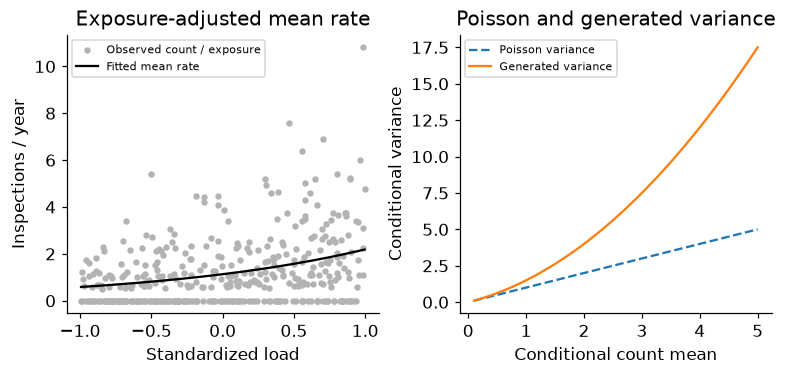

In [2]:
from scipy.special import expit
from scipy.optimize import minimize,check_grad
from sklearn.linear_model import LogisticRegression,PoissonRegressor
from sklearn.metrics import brier_score_loss,log_loss,mean_squared_error
def generate(n):
 z=rng.uniform(-1,1,n);e=rng.uniform(.5,2,n);prob=expit(-1+.9*z);mu=e*np.exp(.1+.7*z);failure=rng.binomial(1,prob);counts=rng.poisson(mu*rng.gamma(2,.5,n));return z,e,prob,mu,failure,counts
tr=generate(600);dev=generate(200);te=generate(400);z,e,prob,mu,failure,counts=tr;Z=np.column_stack([np.ones(len(z)),z]);off=np.log(e)
def objective(b):
 eta=Z@b+off;return float(np.mean(np.exp(eta)-counts*eta))
def gradient(b):return Z.T@(np.exp(Z@b+off)-counts)/len(z)
err=check_grad(objective,gradient,np.array([.2,.5]));assert err<1e-5
fit=minimize(objective,np.zeros(2),jac=gradient,method='BFGS',options={'gtol':1e-8});assert fit.success,fit.message
weighted=PoissonRegressor(alpha=0,max_iter=1000,tol=1e-10).fit(z[:,None],counts/e,sample_weight=e);np.testing.assert_allclose(fit.x,np.r_[weighted.intercept_,weighted.coef_],atol=2e-5)
logistic=LogisticRegression(C=1,max_iter=1000).fit(z[:,None],failure);zt,et,pt,mut,ft,ct=te;estimated=et*np.exp(fit.x[0]+fit.x[1]*zt);pf=logistic.predict_proba(zt[:,None])[:,1];assert np.all(estimated>0) and np.all((pf>0)&(pf<1))
train_est=np.exp(Z@fit.x+off);RESULTS['count_fit']={'offset_coefficients':fit.x.tolist(),'true_coefficients':[.1,.7],'gradient_error':float(err),'weighted_rate_equivalence_passed':True,'training_pearson_dispersion':float(np.sum((counts-train_est)**2/train_est)/(len(z)-2)),'final_mean_squared_count_error':float(mean_squared_error(ct,estimated)),'final_pearson_ratio_mean':float(np.mean((ct-estimated)**2/estimated)),'final_count_mean':float(ct.mean()),'final_prediction_mean':float(estimated.mean())};RESULTS['failure_fit']={'final_brier':float(brier_score_loss(ft,pf)),'final_log_loss':float(log_loss(ft,pf)),'final_events':int(ft.sum()),'final_rows':400};RESULTS['roles']={'train':600,'reserved_development_unused':200,'final':400,'no_selection':True}
fig,axes=plt.subplots(1,2,figsize=(7,3.3));order=np.argsort(zt);axes[0].scatter(zt,ct/et,s=10,color='.7',label='Observed count / exposure');axes[0].plot(zt[order],np.exp(fit.x[0]+fit.x[1]*zt[order]),color='black',label='Fitted mean rate');axes[0].set(xlabel='Standardized load',ylabel='Inspections / year',title='Exposure-adjusted mean rate');axes[0].legend(fontsize=7)
grid=np.linspace(.1,5,100);axes[1].plot(grid,grid,'--',label='Poisson variance');axes[1].plot(grid,grid+grid**2/2,'-',label='Generated variance');axes[1].set(xlabel='Conditional count mean',ylabel='Conditional variance',title='Poisson and generated variance');axes[1].legend(fontsize=7);plt.show()


<a id="probabilities"></a>
## A count expectation is not a probability of at least one event

For mean count two, Poisson gives P(count>0)=1-exp(-2), whereas the generated Gamma–Poisson mixture gives 1-(1+2/2)^(-2). Mean two itself cannot be a probability. The mixture zero formula follows the Gamma Laplace transform; this exact comparison uses the declared distribution, not a fitted negative-binomial model. Logistic failure has a different event definition and no implied equality to either count probability. Overdispersion diagnostics describe a working-model mismatch, not a formal independent-error significance test.


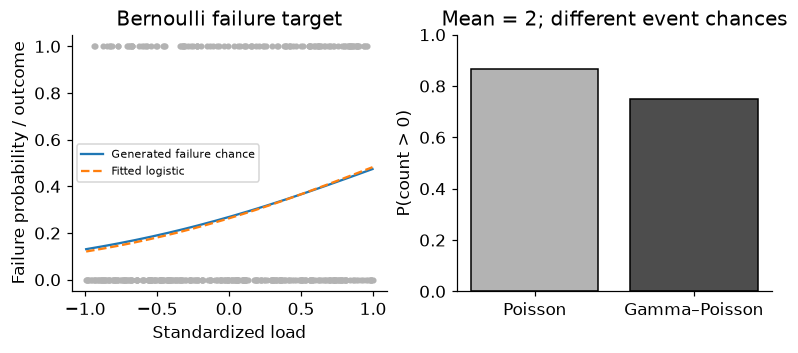

In [3]:
mu0=2.;poisson_event=1-np.exp(-mu0);mixture_event=1-(1+mu0/2)**(-2);assert 0<mixture_event<poisson_event<1 and mu0>1
RESULTS['count_probability_at_mean_two']={'mean':2.,'Poisson_probability_positive':float(poisson_event),'generated_mixture_probability_positive':float(mixture_event),'variance_of_generated_count':4.}
fig,axes=plt.subplots(1,2,figsize=(7,3.1));axes[0].scatter(zt,ft,s=9,color='.7');axes[0].plot(zt[order],pt[order],'-',label='Generated failure chance');axes[0].plot(zt[order],pf[order],'--',label='Fitted logistic');axes[0].set(xlabel='Standardized load',ylabel='Failure probability / outcome',title='Bernoulli failure target');axes[0].legend(fontsize=7)
axes[1].bar(['Poisson','Gamma–Poisson'],[poisson_event,mixture_event],color=['.7','.3'],edgecolor='black');axes[1].set(ylim=(0,1),ylabel='P(count > 0)',title='Mean = 2; different event chances');plt.show()


In [4]:
summary={'example_id':'code_073','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['Bernoulli logit versus count log-mean', 'exposure offset and weighted rates', 'Poisson mean versus overdispersion', 'count means are not event probabilities'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["Bernoulli logit versus count log-mean", "exposure offset and weighted rates", "Poisson mean versus overdispersion", "count means are not event probabilities"], "elapsed_seconds": 0.271, "example_id": "code_073", "hardware": "Darwin arm64 CPU", "results": {"count_fit": {"final_count_mean": 1.5225, "final_mean_squared_count_error": 2.6455478142285913, "final_pearson_ratio_mean": 1.5804343798376632, "final_prediction_mean": 1.5447327258397672, "gradient_error": 1.64063485248818e-08, "offset_coefficients": [0.1223195428924368, 0.6615077773916107], "training_pearson_dispersion": 1.6200140460636812, "true_coefficients": [0.1, 0.7], "weighted_rate_equivalence_passed": true}, "count_probability_at_mean_two": {"Poisson_probability_positive": 0.8646647167633873, "generated_mixture_probability_positive": 0.75, "mean": 2.0, "variance_of_generated_count": 4.0}, "failure_fit": {"final_brier": 0.20586770115377356, "final_events": 121, "final_log_loss